In [1]:
import os, sys, time
import json, math, random
import numpy as np
import torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
BASE = './content/q2'
out = f'{BASE}/outputs'
ckpt = f'{BASE}/checkpoints'
os.makedirs(out, exist_ok=True)
os.makedirs(ckpt, exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(dev)
hardware = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = True
print(hardware)

cuda
Tesla T4


In [3]:
from torchvision.datasets import MovingMNIST

ds = MovingMNIST(root = './content/data', split=None, download=True)
if hasattr(ds, 'data'):
  all = ds.data
else:
  items = []
  for i in range(len(ds)):
    items.append(ds[i])
  all = torch.stack(items)

all = all.to(torch.uint8)
print(all.shape, all.dtype)


100%|██████████| 819M/819M [00:20<00:00, 40.1MB/s]


torch.Size([10000, 20, 1, 64, 64]) torch.uint8


In [4]:
train = all[0:8000].to(dev)
val = all[8000:9000].to(dev)
test = all[9000:10000].to(dev)

def to_float(v):
  return v.float()/255.0

print(train.shape, val.shape, test.shape)
# print(train.dtype, val.dtype, test.dtype)

torch.Size([8000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64])


In [5]:
#transformations and windows
def M(x):
  return x.flip(-1)

def R(x, a=1):
  return torch.rot90(x,a, dims=(-2,-1))

G = []
for m in (0, 1):
 for a in range(4):
  G.append((a, m))

def g_apply(x,g):
  a, m =g
  y = R(x, a)
  return M(y) if m else y

def g_inv(x, g):
  a, m = g
  return M(R(x, a)) if m else R(x,-a)

def window_idx(t,k):
  ar = torch.arange(10, device = t.device)
  f = t[:, None]+k[:,None]*ar[None]
  return f.clamp(max=20)-1, f<=20

def make_windows(vids, t, k , scale= True):
  t = t.to(vids.device)
  k = k.to(vids.device)
  idx, valid = window_idx(t, k)

  fr = vids[torch.arange(vids.shape[0], device=vids.device)[:, None], idx].float()
  if scale:
    fr = fr / 255.0

  X = fr[:, :5]
  Y = fr[:, 5:]
  m = valid[:, 5:]

  Y = Y * m[:, :, None, None, None]
  return X, Y, m

In [6]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7, 0, 10, 20] = 1

md = lambda a, b: (a - b).abs().max().item()

def bright(v):
  f, c, r, col = (v == 1).nonzero()[0].tolist()
  return (f, r, col)

fv = torch.arange(1, 21).float()[:, None, None, None].expand(20, 1, 64, 64).contiguous()

def win(k):
  X, Y, m = make_windows(fv[None], torch.tensor([1]), torch.tensor([k]), scale=False)
  return (', '.join(map(str, X[0, :, 0, 0, 0].long().tolist()))+' / '+', '.join(map(str, Y[0, m[0], 0, 0, 0].long().tolist())))

checking_rows = [
 ('(a) max|M(M(x)) − x|', '0', f'{md(M(M(x)), x)} (torch.equal={torch.equal(M(M(x)), x)})'),
 ('(b) max|R⁴(x) − x|', '0', f'{md(R(x,4), x)} (torch.equal={torch.equal(R(x,4), x)})'),
 ('(c) max|MRM(x) − R⁻¹(x)|', '0', f'{md(M(R(M(x))), R(x,-1))} (torch.equal={torch.equal(M(R(M(x))), R(x,-1))})'),
 ('(d) bright pixel of M(p)', '(7, 10, 43)', str(bright(M(p)))),
 ('(e) bright pixel of R(p)', '(7, 43, 10)', str(bright(R(p)))),
 ('(f) 1× input / target', '1–5 / 6–10', win(1)),
 ('(g) 2× input / target', '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19', win(2)),
 ('(h) 3× input / target', '1, 4, 7, 10, 13 / 16, 19', win(3)),
]
table1 = pd.DataFrame(checking_rows, columns=['check', 'expected', 'mines'])
table1.to_csv(f'{out}/table1.csv', index=False)
table1

,check,expected,mines
0,(a) max|M(M(x)) − x|,0,0.0 (torch.equal=True)
1,(b) max|R⁴(x) − x|,0,0.0 (torch.equal=True)
2,(c) max|MRM(x) − R⁻¹(x)|,0,0.0 (torch.equal=True)
3,(d) bright pixel of M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) bright pixel of R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1× input / target,1–5 / 6–10,"1, 2, 3, 4, 5 / 6, 7, 8, 9, 10"
6,(g) 2× input / target,"1, 3, 5, 7, 9 / 11, 13, 15, 17, 19","1, 3, 5, 7, 9 / 11, 13, 15, 17, 19"
7,(h) 3× input / target,"1, 4, 7, 10, 13 / 16, 19","1, 4, 7, 10, 13 / 16, 19"


pixels kept: 103050, median speed: 3.3175
2x = 6.6350, 3x = 9.9525


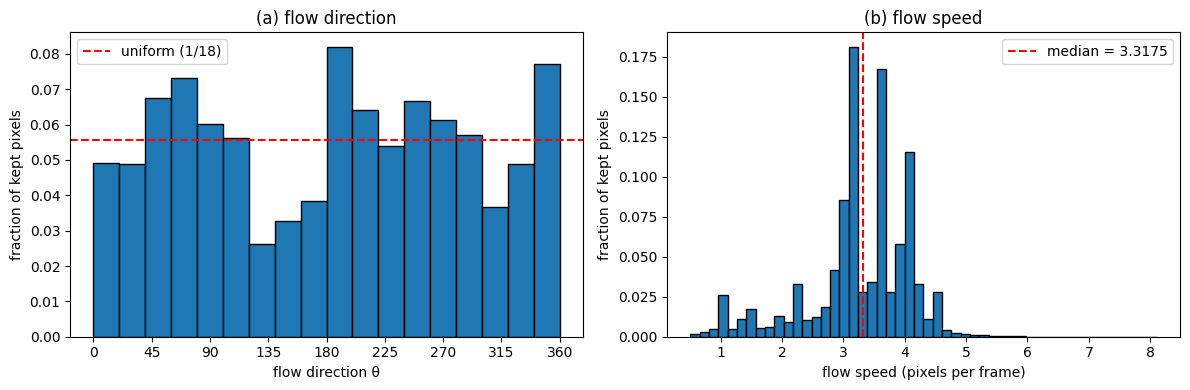

In [7]:
import cv2

vids = train[:50].cpu().numpy()

dxs = []
dys = []
for v in range(50):
 for s in range(19):
  prev = vids[v, s, 0]
  nxt = vids[v, s + 1, 0]
  flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
  dx, dy = flow[..., 0], flow[..., 1]
  keep = (prev > 51) & (nxt > 51) & (np.hypot(dx, dy) > 0.5)
  dxs.append(dx[keep])
  dys.append(dy[keep])

dx = np.concatenate(dxs)
dy = np.concatenate(dys)

theta = np.degrees(np.arctan2(-dy, dx)) % 360
speed = np.hypot(dx, dy)
n, med = len(speed), np.median(speed)
print(f'pixels kept: {n}, median speed: {med:.4f}')
print(f'2x = {2*med:.4f}, 3x = {3*med:.4f}')

w = np.ones(n) / n
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(theta, bins=np.arange(0, 361, 20), weights=w, edgecolor='k')
ax[0].axhline(1/18, color='r', ls='--', label='uniform (1/18)')
ax[0].set_xticks(range(0, 361, 45))
ax[0].set_xlabel('flow direction θ')
ax[0].set_ylabel('fraction of kept pixels')
ax[0].set_title('(a) flow direction')
ax[0].legend()

ax[1].hist(speed, bins=50, weights=w, edgecolor='k')
ax[1].axvline(med, color='r', ls='--', label=f'median = {med:.4f}')
ax[1].set_xlabel('flow speed (pixels per frame)')
ax[1].set_ylabel('fraction of kept pixels')
ax[1].set_title('(b) flow speed')
ax[1].legend()

plt.tight_layout()
plt.savefig(f'{out}/figure1.png', dpi=150)
plt.show()

In [8]:
#baseline

class ConvLSTMCell(nn.Module):
  def __init__(self, cin, ch=64, k=3, dil=1):
    super().__init__()
    self.conv = nn.Conv2d(cin + ch, 4 * ch, k, padding=dil * (k // 2), dilation=dil)

  def forward(self, u, h, c):
    i, f, o, g = self.conv(torch.cat([u, h], 1)).chunk(4, 1)
    c = torch.sigmoid(f)*c + torch.sigmoid(i) * torch.tanh(g)
    h = torch.sigmoid(o)*torch.tanh(c)
    return h, c

class ConvLSTMForecaster(nn.Module):
  def __init__(self, dil=(1, 1)):
    super().__init__()
    self.l1 = ConvLSTMCell(16, 64, 3, dil[0])
    self.l2 = ConvLSTMCell(64, 64, 3, dil[1])
    self.head = nn.Conv2d(64, 16,
                          1)
  def step(self, x, st):
    u = F.pixel_unshuffle(x, 4)
    h1, c1, h2, c2 = st
    h1, c1 = self.l1(u, h1, c1)
    h2, c2 = self.l2(h1, h2, c2)
    y = torch.sigmoid(F.pixel_shuffle(self.head(h2), 4))
    return y, (h1, c1, h2, c2)

  def forward(self, X):
    z = X.new_zeros(X.shape[0], 64, 16, 16)
    st = (z, z, z, z)
    for tau in range(5):
      y, st = self.step(X[:, tau], st)
    preds = [y]
    for _ in range(4):
      y, st = self.step(y, st)
      preds.append(y)
    return torch.stack(preds, 1)

def count_params(m):
  total = 0
  for p in m.parameters():
    if p.requires_grad:
      total += p.numel()
  return total
print(count_params(ConvLSTMForecaster()))

480784


In [9]:
MAX_T = {1: 14, 2: 8, 3: 2}

def masked_mse(pred, Y, m):
  per = ((pred - Y) ** 2).mean(dim=(2, 3, 4))
  return ((per * m).sum(1) / m.sum(1)).mean()

def train_model(name, seed, sym_aug=False, speed_aug=False, dil=(1, 1), epochs=30, bs=32):
  torch.manual_seed(seed)
  np.random.seed(seed)
  random.seed(seed)

  gen = torch.Generator().manual_seed(seed)
  model = ConvLSTMForecaster(dil).to(dev)
  opt = torch.optim.Adam(model.parameters(), lr=1e-3)

  N = train.shape[0]
  ep_times = []

  for ep in range(epochs):
    model.train()
    t0 = time.time()
    tot = 0
    perm = torch.randperm(N, generator=gen)

    for i in range(0, N, bs):
      idx = perm[i:i + bs]
      B = len(idx)
      if speed_aug:
        k = torch.randint(1, 4, (B,), generator=gen)
        tmax = torch.tensor([MAX_T[int(v)] for v in k])
        t = 1 + (torch.rand(B, generator=gen) * tmax).long()
      else:
        k = torch.ones(B, dtype=torch.long)
        t = torch.randint(1, 12, (B,), generator=gen)

      X, Y, m = make_windows(train[idx.to(dev)], t, k)
      if sym_aug:
        gi = torch.randint(0, 8, (B,), generator=gen)
        for j in range(8):
          sel = (gi == j).to(dev)
          if sel.any():
            X[sel] = g_apply(X[sel], G[j])
            Y[sel] = g_apply(Y[sel], G[j])

      loss = masked_mse(model(X), Y, m.float())
      opt.zero_grad()
      loss.backward()
      opt.step()
      tot += loss.item() * B

    torch.cuda.synchronize()
    ep_times.append(time.time() - t0)
    print(f'{name} seed{seed} epoch {ep+1}/{epochs} loss {tot/N:.5f} {ep_times[-1]:.1f}s')

  torch.save(model.state_dict(), f'{ckpt}/{name}_seed{seed}.pt')
  return model, float(np.mean(ep_times))

In [10]:
modelA = {}
timeA = {}
for s in (0, 1):
  modelA[s], timeA[s] = train_model('A', s)
print(timeA)

A seed0 epoch 1/30 loss 0.04611 12.5s
A seed0 epoch 2/30 loss 0.03967 9.8s
A seed0 epoch 3/30 loss 0.03867 9.9s
A seed0 epoch 4/30 loss 0.03713 10.0s
A seed0 epoch 5/30 loss 0.03526 10.1s
A seed0 epoch 6/30 loss 0.03359 10.2s
A seed0 epoch 7/30 loss 0.03225 10.3s
A seed0 epoch 8/30 loss 0.03131 10.5s
A seed0 epoch 9/30 loss 0.03040 10.5s
A seed0 epoch 10/30 loss 0.02975 10.5s
A seed0 epoch 11/30 loss 0.02930 10.4s
A seed0 epoch 12/30 loss 0.02876 10.3s
A seed0 epoch 13/30 loss 0.02838 10.3s
A seed0 epoch 14/30 loss 0.02803 10.3s
A seed0 epoch 15/30 loss 0.02756 10.4s
A seed0 epoch 16/30 loss 0.02717 10.4s
A seed0 epoch 17/30 loss 0.02686 10.5s
A seed0 epoch 18/30 loss 0.02638 10.4s
A seed0 epoch 19/30 loss 0.02614 10.4s
A seed0 epoch 20/30 loss 0.02568 10.4s
A seed0 epoch 21/30 loss 0.02531 10.4s
A seed0 epoch 22/30 loss 0.02501 10.4s
A seed0 epoch 23/30 loss 0.02445 10.4s
A seed0 epoch 24/30 loss 0.02424 10.4s
A seed0 epoch 25/30 loss 0.02386 10.4s
A seed0 epoch 26/30 loss 0.02366 10.

In [11]:
def fmt(v):
  v = float(v)
  if v == 0:
    return '0'
  if abs(v) < 1e-3:
    return f'{v:.2e}'
  else:
    return f'{v:.3g}'

def fmt_seeds(a, b):
  return f'{fmt((a + b) / 2)} ({fmt(a)}, {fmt(b)})'

@torch.no_grad()
def predict_all(f, vids, k=1, t=1, T=None, bs=32):
  Xs, Ys, Ms, Ps = [], [], [], []
  for i in range(0, vids.shape[0], bs):
    v = vids[i:i + bs]
    B = v.shape[0]

    X, Y, m = make_windows(v, torch.full((B,), t), torch.full((B,), k))
    if T is not None:
      X= T(X)
      Y= T(Y)
    Xs.append(X.cpu())
    Ys.append(Y.cpu())
    Ms.append(m.cpu())
    Ps.append(f(X).cpu())
  return torch.cat(Xs), torch.cat(Ys), torch.cat(Ms), torch.cat(Ps)

def per_video_mse(P, Y):
  return ((P - Y) ** 2).mean(dim=(2, 3, 4))

def model_fn(model):
  model.eval()
  return lambda X: model(X)

blank = lambda X: torch.zeros_like(X)
copy_last = lambda X: X[:, -1:].expand(-1, 5, -1, -1, -1).clone()

@torch.no_grad()
def inference_time(f, vids, bs=32):
  batches = []
  for i in range(0, vids.shape[0], bs):
    v = vids[i:i + bs]
    B = v.shape[0]
    X, _, _ = make_windows(v, torch.ones(B, dtype=torch.long), torch.ones(B, dtype=torch.long))
    batches.append(X)

  torch.cuda.synchronize()
  t0 = time.time()
  for X in batches:
      f(X)
  torch.cuda.synchronize()
  return time.time() - t0

In [12]:
resA = {}
for s in (0, 1):
  _, Y, m, P = predict_all(model_fn(modelA[s]), test)
  resA[s] = per_video_mse(P, Y).mean(0)

_, Y, m, Pb = predict_all(blank, test)
rb = per_video_mse(Pb, Y).mean(0)

_, _, _, Pc = predict_all(copy_last, test)
rc = per_video_mse(Pc, Y).mean(0)

rows = []
row_a = ['Model A']
for h in range(5):
  row_a.append(fmt_seeds(resA[0][h], resA[1][h]))
row_a.append(fmt_seeds(resA[0].mean(), resA[1].mean()))
row_a.append(f'{count_params(modelA[0]):,}')
rows.append(row_a)

row_blank = ['Blank']
for h in range(5):
  row_blank.append(fmt(rb[h]))
row_blank.append(fmt(rb.mean()))
row_blank.append('0')
rows.append(row_blank)

row_copy = ['Copy-last']
for h in range(5):
  row_copy.append(fmt(rc[h]))
row_copy.append(fmt(rc.mean()))
row_copy.append('0')
rows.append(row_copy)

table2 = pd.DataFrame(rows, columns=['Model', 'MSE1', 'MSE2', 'MSE3', 'MSE4', 'MSE5', 'E(5)', 'Params'])
table2.to_csv(f'{out}/table2.csv', index=False)

infA = {s: inference_time(model_fn(modelA[s]), test) for s in (0, 1)}
print('inference time (s):', infA, ' train time/epoch (s):', timeA)
table2

inference time (s): {0: 0.42142605781555176, 1: 0.4240880012512207}  train time/epoch (s): {0: 10.409964005152384, 1: 10.376454329490661}


,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),Params
0,Model A,"0.0172 (0.0175, 0.017)","0.0205 (0.0208, 0.0203)","0.0228 (0.0231, 0.0225)","0.0245 (0.0248, 0.0242)","0.0262 (0.0264, 0.0259)","0.0222 (0.0225, 0.022)","480,784"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


candidate overlap videos: [191, 750, 909, 728, 623]


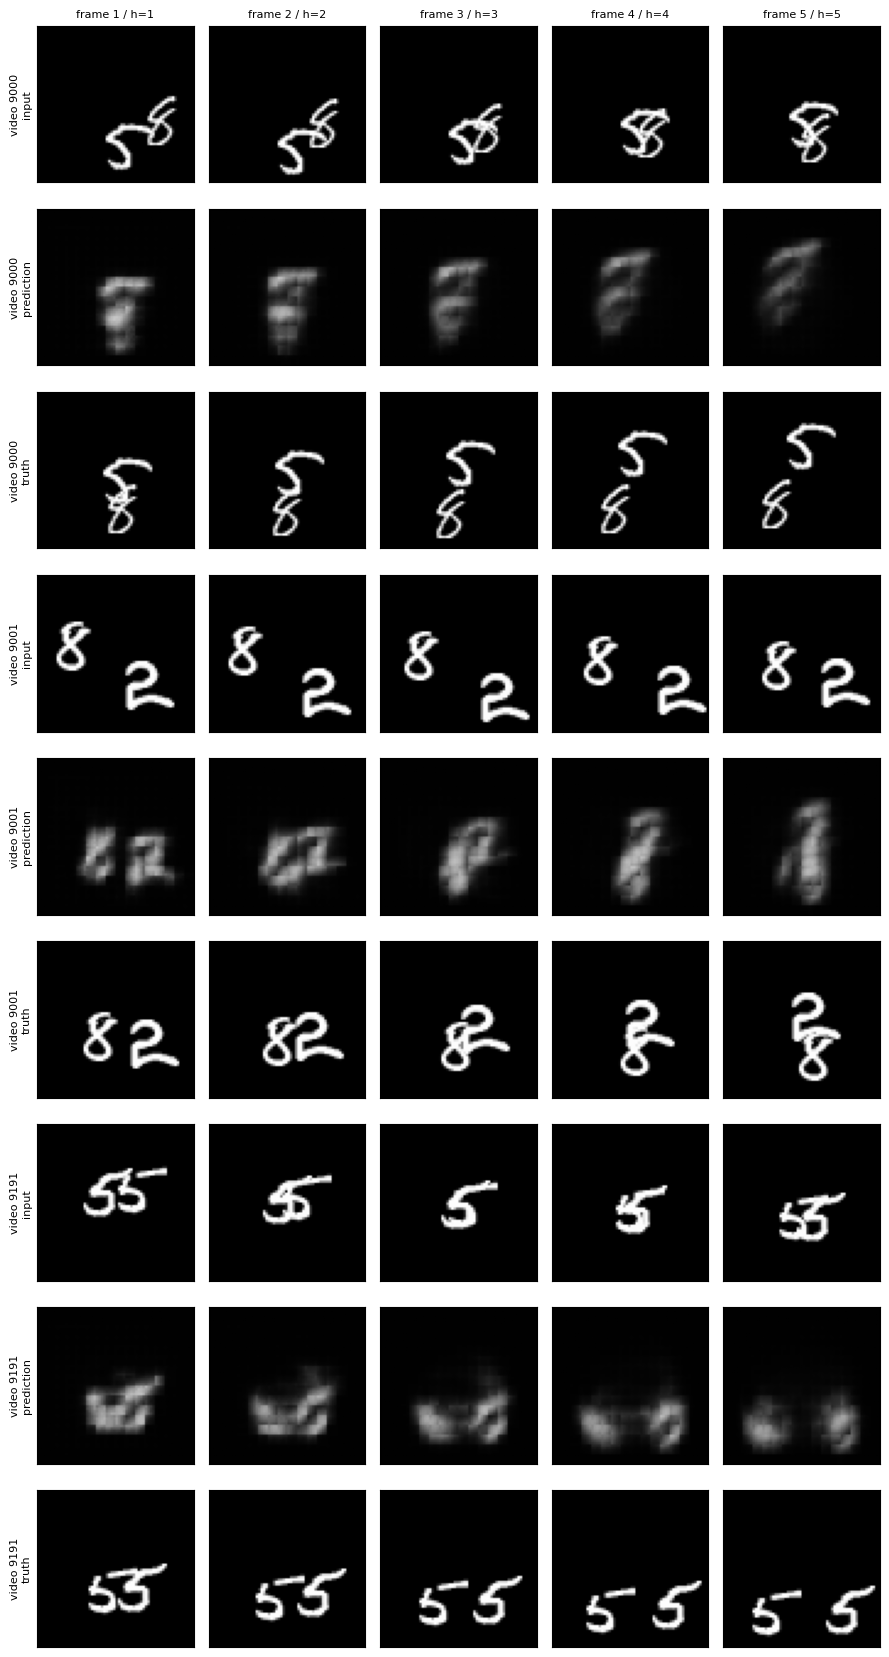

In [13]:
area = (test[:, :10, 0] > 51).flatten(2).sum(-1).float()
ov = (area.min(1).values / area.max(1).values).argsort()[:5].tolist()
print('candidate overlap videos:', ov)

def plot_fig2(ids, model, fname):
  X, Y, m, P = predict_all(model_fn(model), test[ids])
  fig, ax = plt.subplots(3 * len(ids), 5, figsize=(9, 5.6 * len(ids)))

  for r, vid in enumerate(ids):
    for j in range(5):
      for q, img in enumerate([X[r, j], P[r, j], Y[r, j]]):
        a = ax[3 * r + q, j]
        a.imshow(img[0], cmap='gray', vmin=0, vmax=1)
        a.set_xticks([])
        a.set_yticks([])

        if r == 0 and q == 0:
          a.set_title(f'frame {j+1} / h={j+1}', fontsize=8)
        if j == 0:
          a.set_ylabel(f'video {9000+vid}\n' + ['input', 'prediction', 'truth'][q], fontsize=8)

  plt.tight_layout()
  plt.savefig(f'{out}/{fname}', dpi=120)
  plt.show()

plot_fig2([0, 1, ov[0]], modelA[0], 'figure2.png')

In [14]:
#testing the baselines
import imageio.v2 as imageio

os.makedirs(f'{out}/gifs', exist_ok=True)

TM = lambda x: M(x)
TR = lambda x: R(x, 1)

@torch.no_grad()
def sym_metrics(f, vids, bs=32):
  keys = ['E5', 'CM', 'EM', 'CR', 'ER']
  res = {}
  for k in keys:
    res[k] = []

  for i in range(0, vids.shape[0], bs):
    v = vids[i:i + bs]
    B = v.shape[0]
    ones = torch.ones(B, dtype=torch.long)
    X, Y, _ = make_windows(v, ones, ones)

    fX = f(X)
    err5 = ((fX - Y) ** 2).mean(dim=(1, 2, 3, 4)).cpu()
    res['E5'].append(err5)

    transforms = (('M', TM), ('R', TR))
    for name, T in transforms:
      fTX = f(T(X))
      errC = ((fTX - T(fX)) ** 2).mean(dim=(1, 2, 3, 4)).cpu()
      errE = ((fTX - T(Y)) ** 2).mean(dim=(1, 2, 3, 4)).cpu()
      res['C' + name].append(errC)
      res['E' + name].append(errE)

  out = {}
  for k in keys:
    out[k] = torch.cat(res[k])
  return out

symA = {}
for s in (0, 1):
  symA[s] = sym_metrics(model_fn(modelA[s]), test)

symBlank = sym_metrics(blank, test)
symCopy = sym_metrics(copy_last, test)

cols = ['E5', 'CM', 'EM', 'CR', 'ER']
rows = []
row_a = ['Model A']
for c in cols:
  row_a.append(fmt_seeds(symA[0][c].mean(), symA[1][c].mean()))
rows.append(row_a)

row_blank = ['Blank']
for c in cols:
  row_blank.append(fmt(symBlank[c].mean()))
rows.append(row_blank)

row_copy = ['Copy-last']
for c in cols:
  row_copy.append(fmt(symCopy[c].mean()))
rows.append(row_copy)

table3 = pd.DataFrame(rows, columns=['Model', 'E(5)', 'C_M', 'E_M', 'C_R', 'E_R'])
table3.to_csv(f'{out}/table3.csv', index=False)
table3

,Model,E(5),C_M,E_M,C_R,E_R
0,Model A,"0.0222 (0.0225, 0.022)","0.00163 (0.00155, 0.00171)","0.0228 (0.0231, 0.0226)","0.00288 (0.00254, 0.00321)","0.024 (0.024, 0.0239)"
1,Blank,0.0426,0,0.0426,0,0.0426
2,Copy-last,0.0641,0,0.0641,0,0.0641


top C_M: [9269, 9499]  top C_R: [9031, 9150]


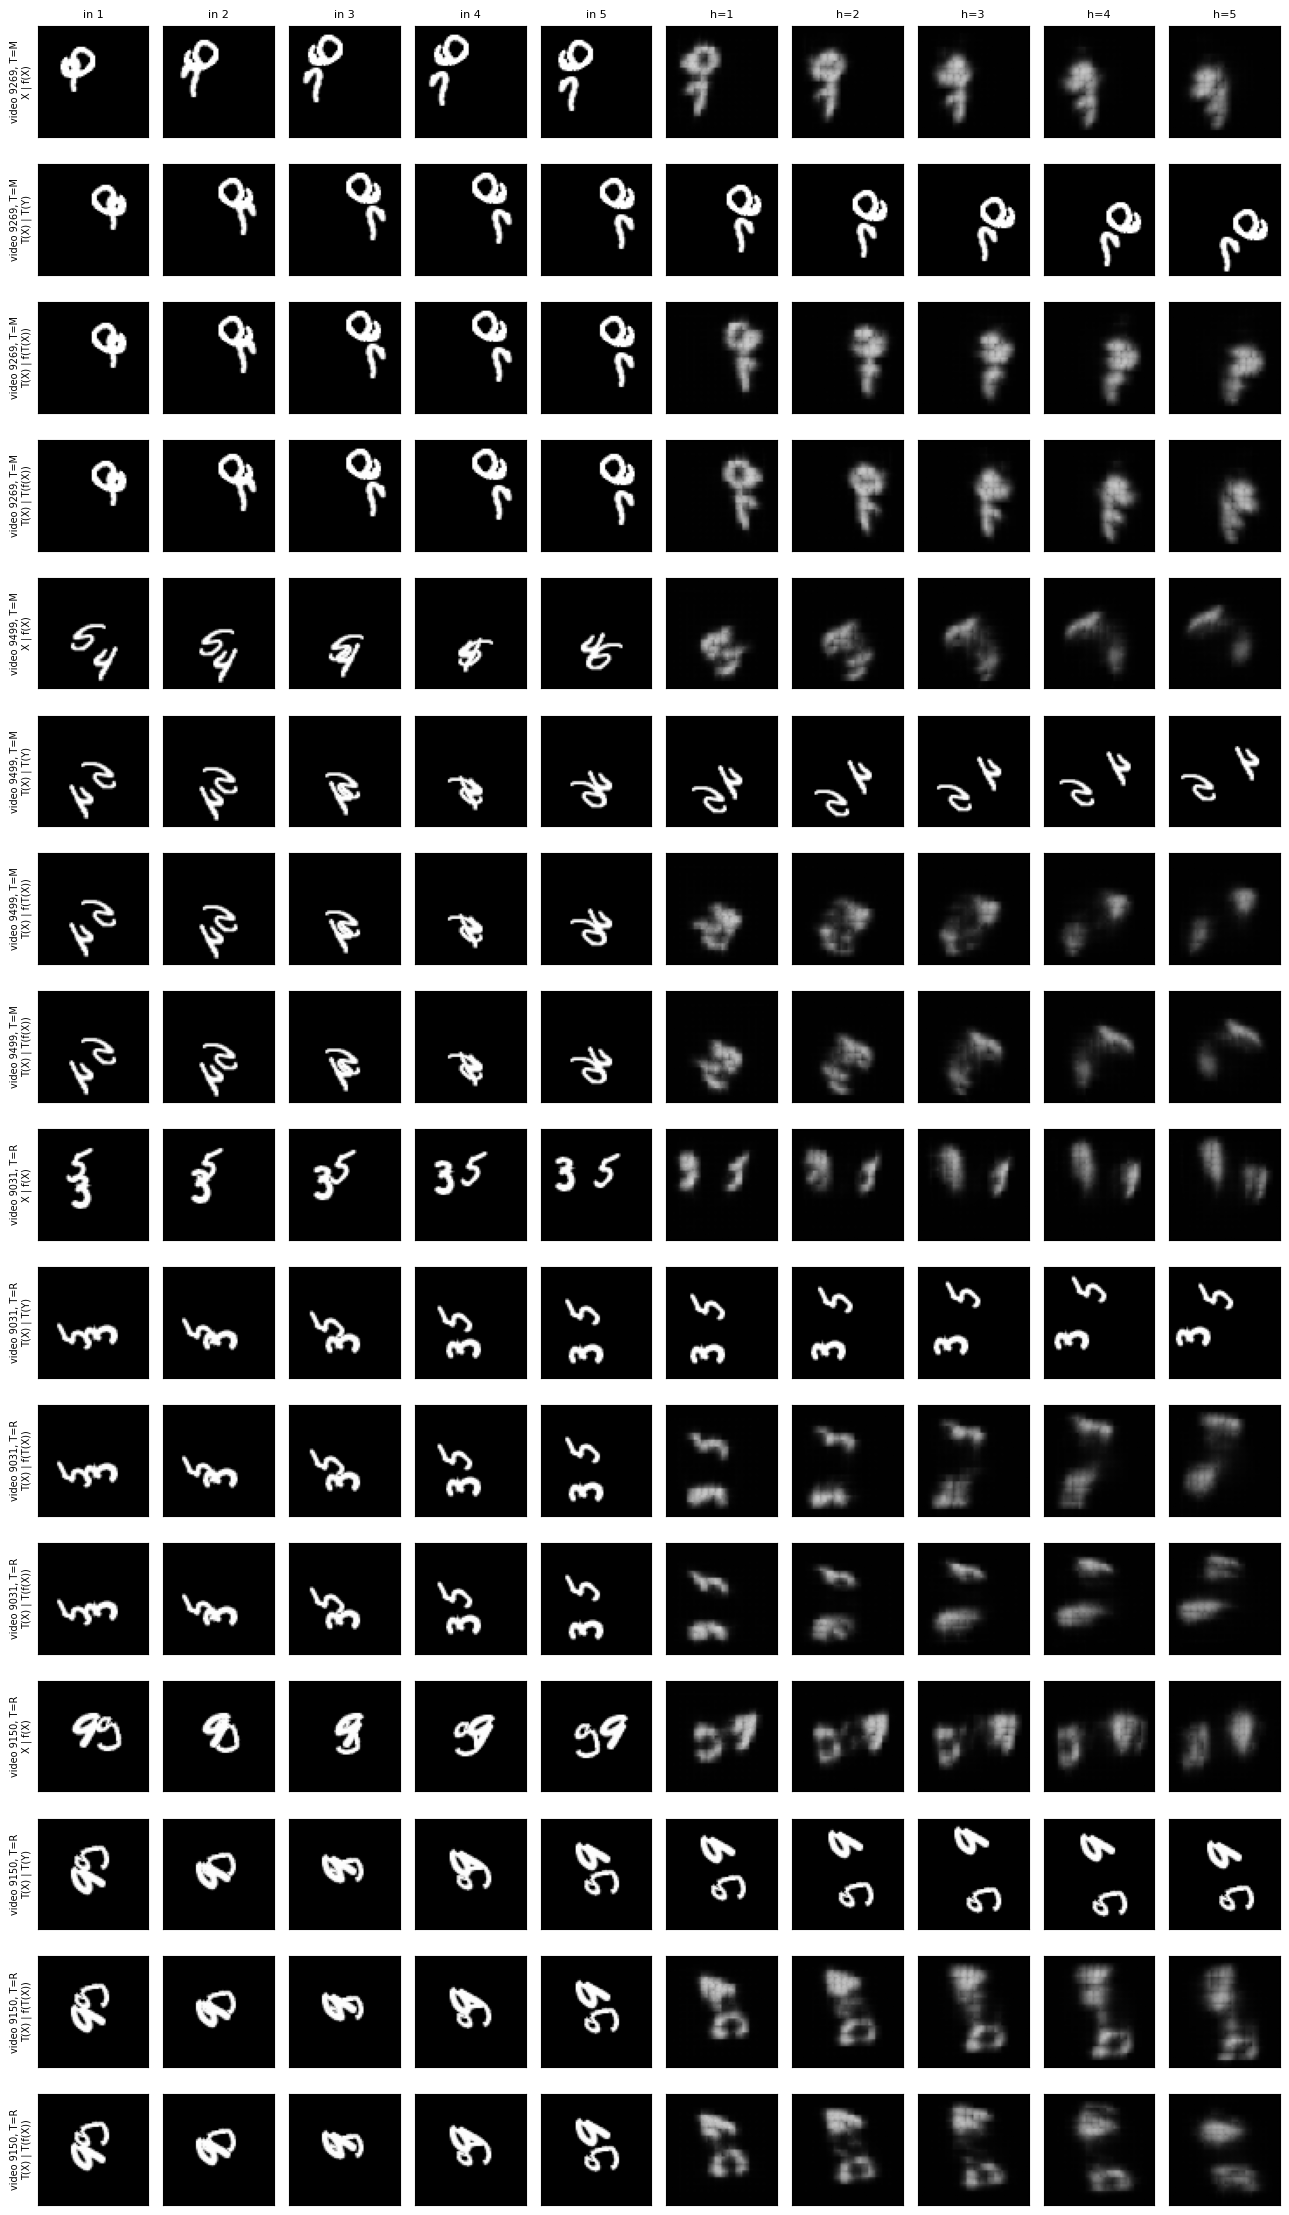

./content/q2/outputs/gifs/fig3_A_video9269_M.gif
./content/q2/outputs/gifs/fig3_A_video9499_M.gif
./content/q2/outputs/gifs/fig3_A_video9031_R.gif
./content/q2/outputs/gifs/fig3_A_video9150_R.gif


In [15]:
@torch.no_grad()
def fig3_rows(f, vid, T):
  v = test[vid:vid + 1]
  X, Y, _ = make_windows(v, torch.ones(1, dtype=torch.long), torch.ones(1, dtype=torch.long))
  fX = f(X)
  TX = T(X)
  return [(X, fX), (TX, T(Y)), (TX, f(TX)), (TX, T(fX))]

row_names = ['X | f(X)', 'T(X) | T(Y)', 'T(X) | f(T(X))', 'T(X) | T(f(X))']

def plot_fig3(f, picks, fname):
  fig, ax = plt.subplots(4 * len(picks), 10, figsize=(13, 5.6 * len(picks)))

  for p, (vid, tname, T) in enumerate(picks):
    for r, (left, right) in enumerate(fig3_rows(f, vid, T)):
      for j in range(10):
        img = left[0, j] if j < 5 else right[0, j - 5]
        a = ax[4 * p + r, j]
        a.imshow(img[0].cpu(), cmap='gray', vmin=0, vmax=1)
        a.set_xticks([])
        a.set_yticks([])

        if p == 0 and r == 0:
          if j <5:
            a.set_title(f'in {j+1}', fontsize=8)
          else:
            a.set_title(f'h={j-4}', fontsize=8)

        if j == 0:
          a.set_ylabel(f'video {9000+vid}, T={tname}\n{row_names[r]}', fontsize=7)

  plt.tight_layout()
  plt.savefig(f'{out}/{fname}', dpi=110)
  plt.show()

def make_gif(f, vid, T, path):
  rows4 = fig3_rows(f, vid, T)
  frames = []
  for h in range(5):
    tiles = []
    for left, right in rows4:
      tiles.append(torch.cat([left[0, -1, 0].cpu(), torch.ones(64, 2), right[0, h, 0].cpu()], 1))
      tiles.append(torch.ones(2, 130))

    fr = (torch.cat(tiles, 0).clamp(0, 1).numpy() * 255).astype(np.uint8)
    frames.append(np.kron(fr, np.ones((3, 3), dtype=np.uint8)))
  imageio.mimsave(path, frames, duration=0.8, loop=0)

fA0 = model_fn(modelA[0])
topM = symA[0]['CM'].argsort(descending=True)[:2].tolist()
topR = symA[0]['CR'].argsort(descending=True)[:2].tolist()

picks = [(v, 'M', TM) for v in topM] + [(v, 'R', TR) for v in topR]
print('top C_M:', [9000 + v for v in topM], ' top C_R:', [9000 + v for v in topR])

plot_fig3(fA0, picks, 'figure3.png')
for v, tname, T in picks:
  pth = f'{out}/gifs/fig3_A_video{9000+v}_{tname}.gif'
  make_gif(fA0, v, T, pth)
  print(pth)

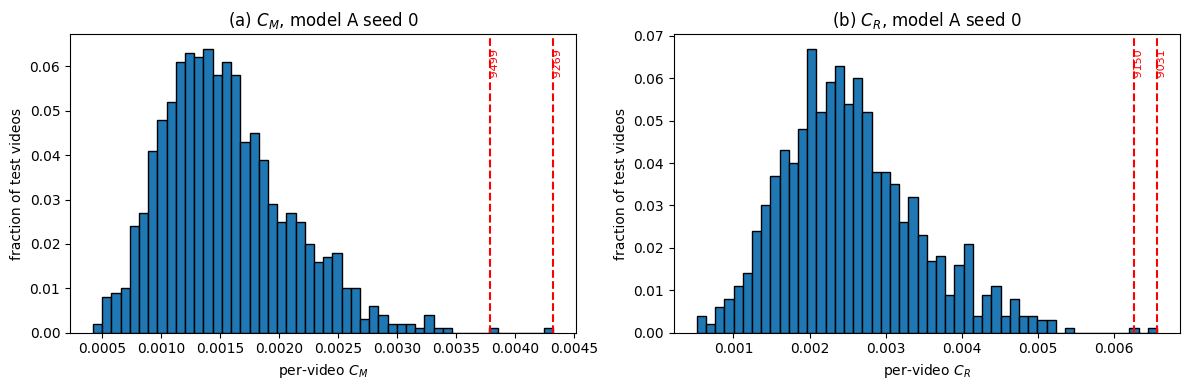

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, c, top, lab in ((ax[0], 'CM', topM, 'a'), (ax[1], 'CR', topR, 'b')):
  vals = symA[0][c].numpy()
  a.hist(vals, bins=50, weights=np.ones(len(vals)) / len(vals), edgecolor='k')
  for v in top:
    a.axvline(vals[v], color='r', ls='--')
    a.text(vals[v], a.get_ylim()[1] * 0.95, f' {9000+v}', color='r', fontsize=8, rotation=90, va='top')

  a.set_xlabel(f'per-video $C_{c[1]}$')
  a.set_ylabel('fraction of test videos')
  a.set_title(f'({lab}) $C_{c[1]}$, model A seed 0')

plt.tight_layout()
plt.savefig(f'{out}/figure4.png', dpi=130)
plt.show()

In [21]:
@torch.no_grad()
def speed_errors(f, vids, k):
  _, Y, m, P = predict_all(f, vids, k=k, t=1)
  return per_video_mse(P, Y), m.float()
def E_n(err, m, n):
  e = err[:, :n]
  mm = m[:, :n]
  return ((e * mm).sum(1) / mm.sum(1)).mean()

# speed error
spA = {}
for s in (0, 1):
  fn = model_fn(modelA[s])
  spA[s] = {}
  for k in (1, 2, 3):
    spA[s][k] = speed_errors(fn, test, k)

spC = {}
for k in (1, 2, 3):
  spC[k] = speed_errors(copy_last, test, k)

cfg = [(1, 2), (2, 2), (3, 2), (1, 5), (2, 5)]

rowA = ['Model A']
rowC = ['Copy-last']
for k, n in cfg:
  rowA.append(fmt_seeds(E_n(*spA[0][k], n), E_n(*spA[1][k], n)))
  rowC.append(fmt(E_n(*spC[k], n)))

print([fmt(E_n(*speed_errors(blank, test, k), 2)) for k in (1, 2, 3)])

table4 = pd.DataFrame( [rowA, rowC],columns=['Model', 'E(2) 1×', 'E(2) 2×', 'E(2) 3×', 'E(5) 1×', 'E(5) 2×'])

table4.to_csv(f'{out}/table4.csv', index=False)
table4


['0.0426', '0.0425', '0.0426']


,Model,E(2) 1×,E(2) 2×,E(2) 3×,E(5) 1×,E(5) 2×
0,Model A,"0.0189 (0.0191, 0.0186)","0.0442 (0.0435, 0.0449)","0.0511 (0.0509, 0.0514)","0.0222 (0.0225, 0.022)","0.0484 (0.0476, 0.0493)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


candidates: [9026, 9029, 9038, 9065, 9067, 9071, 9074, 9080, 9085, 9110]


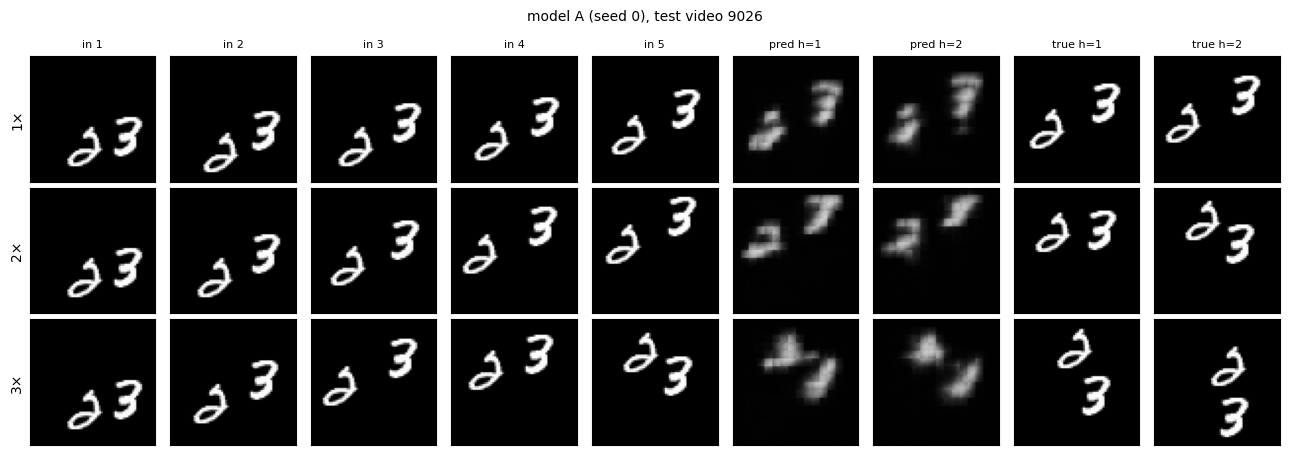

In [27]:
from scipy import ndimage
def n_blobs(img):
  lab, n = ndimage.label(ndimage.binary_dilation(img > 51))
  sizes = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
  return int((sizes > 40).sum())

def separate(v):
  for k in (1, 2, 3):
    for fi in (5 * k, 6 * k):
      if n_blobs(test[v, fi, 0].cpu().numpy()) < 2:
        return False
  return True

good = []
for v in range(test.shape[0]):
  if separate(v):
    good.append(v)

print('candidates:', [9000 + v for v in good[:10]])

def plot_fig5(f, vid, fname, label='model A (seed 0)'):
  fig, ax = plt.subplots(3, 9, figsize=(13, 4.6))
  speeds = (1, 2, 3)

  for r, k in enumerate(speeds):
    X, Y, m, P = predict_all(f, test[vid:vid + 1], k=k, t=1)
    imgs = []
    labs = []

    for j in range(5):
      imgs.append(X[0, j])
      labs.append(f'in {j + 1}')
    for p in (0, 1):
      imgs.append(P[0, p])
      labs.append(f'pred h={p + 1}')
    for p in (0, 1):
      imgs.append(Y[0, p])
      labs.append(f'true h={p + 1}')

    for j in range(len(imgs)):
      a = ax[r, j]
      a.imshow(imgs[j][0], cmap='gray', vmin=0, vmax=1)
      a.set_xticks([])
      a.set_yticks([])
      if r == 0:
        a.set_title(labs[j], fontsize=8)
      if j == 0:
        a.set_ylabel(f'{k}×', fontsize=10)
  plt.suptitle(f'{label}, test video {9000 + vid}', fontsize=10)
  plt.tight_layout()
  plt.savefig(f'{out}/{fname}', dpi=130)
  plt.show()

plot_fig5(model_fn(modelA[0]), good[0], 'figure5.png')

In [22]:
print('D params:', count_params(ConvLSTMForecaster((2, 2))))

models = {'A': modelA}
times = {'A': timeA}

for name, kw in [('B', dict(sym_aug=True)), ('C', dict(speed_aug=True)), ('D', dict(speed_aug=True, dil=(2, 2)))]:
  models[name], times[name] = {}, {}
  for s in (0, 1):
    models[name][s], times[name][s] = train_model(name, s, **kw)
print(times)

D params: 480784
B seed0 epoch 1/30 loss 0.04610 10.8s
B seed0 epoch 2/30 loss 0.03969 11.5s
B seed0 epoch 3/30 loss 0.03865 11.2s
B seed0 epoch 4/30 loss 0.03707 11.1s
B seed0 epoch 5/30 loss 0.03524 11.0s
B seed0 epoch 6/30 loss 0.03358 11.4s
B seed0 epoch 7/30 loss 0.03235 10.8s
B seed0 epoch 8/30 loss 0.03138 10.8s
B seed0 epoch 9/30 loss 0.03056 10.8s
B seed0 epoch 10/30 loss 0.02997 10.9s
B seed0 epoch 11/30 loss 0.02938 11.0s
B seed0 epoch 12/30 loss 0.02896 11.0s
B seed0 epoch 13/30 loss 0.02860 10.9s
B seed0 epoch 14/30 loss 0.02821 10.9s
B seed0 epoch 15/30 loss 0.02779 10.9s
B seed0 epoch 16/30 loss 0.02749 10.9s
B seed0 epoch 17/30 loss 0.02725 10.9s
B seed0 epoch 18/30 loss 0.02681 10.9s
B seed0 epoch 19/30 loss 0.02661 11.0s
B seed0 epoch 20/30 loss 0.02620 11.0s
B seed0 epoch 21/30 loss 0.02594 11.0s
B seed0 epoch 22/30 loss 0.02557 11.0s
B seed0 epoch 23/30 loss 0.02524 10.9s
B seed0 epoch 24/30 loss 0.02494 10.9s
B seed0 epoch 25/30 loss 0.02466 10.9s
B seed0 epoch 26/

In [24]:
summary = {}
for name, ms in models.items():
  summary[name] = {}
  for s in (0, 1):
    f = model_fn(ms[s])
    sm = sym_metrics(f, test)

    sp = {}
    for k in (1, 2, 3):
      sp[k] = speed_errors(f, test, k)

    summary[name][s] = {
      'E5': sm['E5'].mean(), 'CM': sm['CM'].mean(), 'EM': sm['EM'].mean(),
      'CR': sm['CR'].mean(), 'ER': sm['ER'].mean(),
      'E2_1': E_n(*sp[1], 2), 'E2_2': E_n(*sp[2], 2), 'E2_3': E_n(*sp[3], 2),
      'inf': inference_time(f, test), 'train': times[name][s]}

keys = ['E5', 'CM', 'EM', 'CR', 'ER', 'E2_1', 'E2_2', 'E2_3']
rows = []
for name in models:
  r0, r1 = summary[name][0], summary[name][1]

  metric_cells = []
  for k in keys:
    metric_cells.append(fmt_seeds(r0[k], r1[k]))

  rows.append([name] + metric_cells + [f'{count_params(models[name][0]):,}',
    f"{(r0['train'] + r1['train']) / 2:.1f} ({r0['train']:.1f}, {r1['train']:.1f})",
    f"{(r0['inf'] + r1['inf']) / 2:.2f} ({r0['inf']:.2f}, {r1['inf']:.2f})"])

table5 = pd.DataFrame(rows, columns=['Model', 'E(5) 1×', 'C_M', 'E_M', 'C_R', 'E_R', 'E(2) 1×', 'E(2) 2×', 'E(2) 3×', 'Params', 'Train s/epoch', 'Inference s'])
table5.to_csv(f'{out}/table5.csv', index=False)
table5

,Model,E(5) 1×,C_M,E_M,C_R,E_R,E(2) 1×,E(2) 2×,E(2) 3×,Params,Train s/epoch,Inference s
0,A,"0.0222 (0.0225, 0.022)","0.00163 (0.00155, 0.00171)","0.0228 (0.0231, 0.0226)","0.00288 (0.00254, 0.00321)","0.024 (0.024, 0.0239)","0.0189 (0.0191, 0.0186)","0.0442 (0.0435, 0.0449)","0.0511 (0.0509, 0.0514)","480,784","10.4 (10.4, 10.4)","0.42 (0.41, 0.42)"
1,B,"0.0229 (0.0233, 0.0224)","0.00111 (0.00106, 0.00115)","0.0229 (0.0234, 0.0224)","0.00134 (0.00141, 0.00128)","0.0228 (0.0232, 0.0223)","0.0192 (0.0197, 0.0187)","0.0431 (0.0433, 0.0429)","0.049 (0.0496, 0.0483)","480,784","10.9 (11.0, 10.9)","0.42 (0.42, 0.42)"
2,C,"0.0267 (0.0272, 0.0263)","0.00135 (0.00117, 0.00154)","0.0269 (0.0273, 0.0265)","0.00258 (0.0022, 0.00295)","0.0279 (0.0282, 0.0276)","0.0232 (0.0237, 0.0227)","0.0288 (0.0292, 0.0285)","0.0333 (0.0335, 0.0331)","480,784","10.4 (10.3, 10.4)","0.42 (0.42, 0.42)"
3,D,"0.0301 (0.0316, 0.0285)","6.72e-04 (4.81e-04, 8.63e-04)","0.0302 (0.0317, 0.0288)","0.00131 (8.70e-04, 0.00175)","0.0308 (0.032, 0.0295)","0.0277 (0.0292, 0.0262)","0.0303 (0.0315, 0.0291)","0.0325 (0.0335, 0.0316)","480,784","18.5 (18.4, 18.5)","0.85 (0.84, 0.85)"


In [25]:
def symmetrise(model):
  model.eval()
  def fbar(X):
    acc = 0
    for g in G:
      acc = acc + g_inv(model(g_apply(X, g)), g)
    return acc / len(G)
  return fbar

def sci(v):
  return f'{float(v):.2e}'
def sci_seeds(a, b):
  return f'{sci((a + b) / 2)} ({sci(a)}, {sci(b)})'

wrapped = {'Sym-B': ('B', models['B']), 'Sym-D (final)': ('D', models['D'])}
summary6 = {}

for name, (base, ms) in wrapped.items():
  summary6[name] = {}
  for s in (0, 1):
    f = symmetrise(ms[s])
    sm = sym_metrics(f, test)
    sp = {k: speed_errors(f, test, k) for k in (1, 2, 3)}
    summary6[name][s] = {'E5': sm['E5'].mean(), 'CM': sm['CM'].mean(), 'EM': sm['EM'].mean(),
      'CR': sm['CR'].mean(), 'ER': sm['ER'].mean(),
      'E2_1': E_n(*sp[1], 2), 'E2_2': E_n(*sp[2], 2), 'E2_3': E_n(*sp[3], 2),
      'inf': inference_time(f, test), 'train': times[base][s]}

rows = []
for name, (base, ms) in wrapped.items():
  r0, r1 = summary6[name][0], summary6[name][1]
  cells = []
  for k in ['E5', 'CM', 'EM', 'CR', 'ER', 'E2_1', 'E2_2', 'E2_3']:
    if k in ('CM', 'CR'):
      cells.append(sci_seeds(r0[k], r1[k]))
    else:
      cells.append(fmt_seeds(r0[k], r1[k]))

  rows.append([name] + cells + [f'{count_params(ms[0]):,}',
    f"{(r0['train'] + r1['train']) / 2:.1f} ({r0['train']:.1f}, {r1['train']:.1f})",
    f"{(r0['inf'] + r1['inf']) / 2:.2f} ({r0['inf']:.2f}, {r1['inf']:.2f})"])

table6 = pd.DataFrame(rows, columns=['Model', 'E(5) 1×', 'C_M', 'E_M', 'C_R', 'E_R', 'E(2) 1×', 'E(2) 2×', 'E(2) 3×', 'Params', 'Train s/epoch', 'Inference s'])
table6.to_csv(f'{out}/table6.csv', index=False)
table6

,Model,E(5) 1×,C_M,E_M,C_R,E_R,E(2) 1×,E(2) 2×,E(2) 3×,Params,Train s/epoch,Inference s
0,Sym-B,"0.0223 (0.0227, 0.0218)","7.63e-17 (8.23e-17, 7.03e-17)","0.0223 (0.0227, 0.0218)","6.17e-17 (6.68e-17, 5.67e-17)","0.0223 (0.0227, 0.0218)","0.0187 (0.0192, 0.0183)","0.0425 (0.0427, 0.0423)","0.0482 (0.0488, 0.0476)","480,784","10.9 (11.0, 10.9)","3.44 (3.44, 3.44)"
1,Sym-D (final),"0.03 (0.0315, 0.0284)","4.51e-17 (3.55e-17, 5.48e-17)","0.03 (0.0315, 0.0284)","3.47e-17 (2.76e-17, 4.19e-17)","0.03 (0.0315, 0.0284)","0.0277 (0.0292, 0.0263)","0.0303 (0.0314, 0.0291)","0.0324 (0.0334, 0.0314)","480,784","18.5 (18.4, 18.5)","6.64 (6.62, 6.66)"


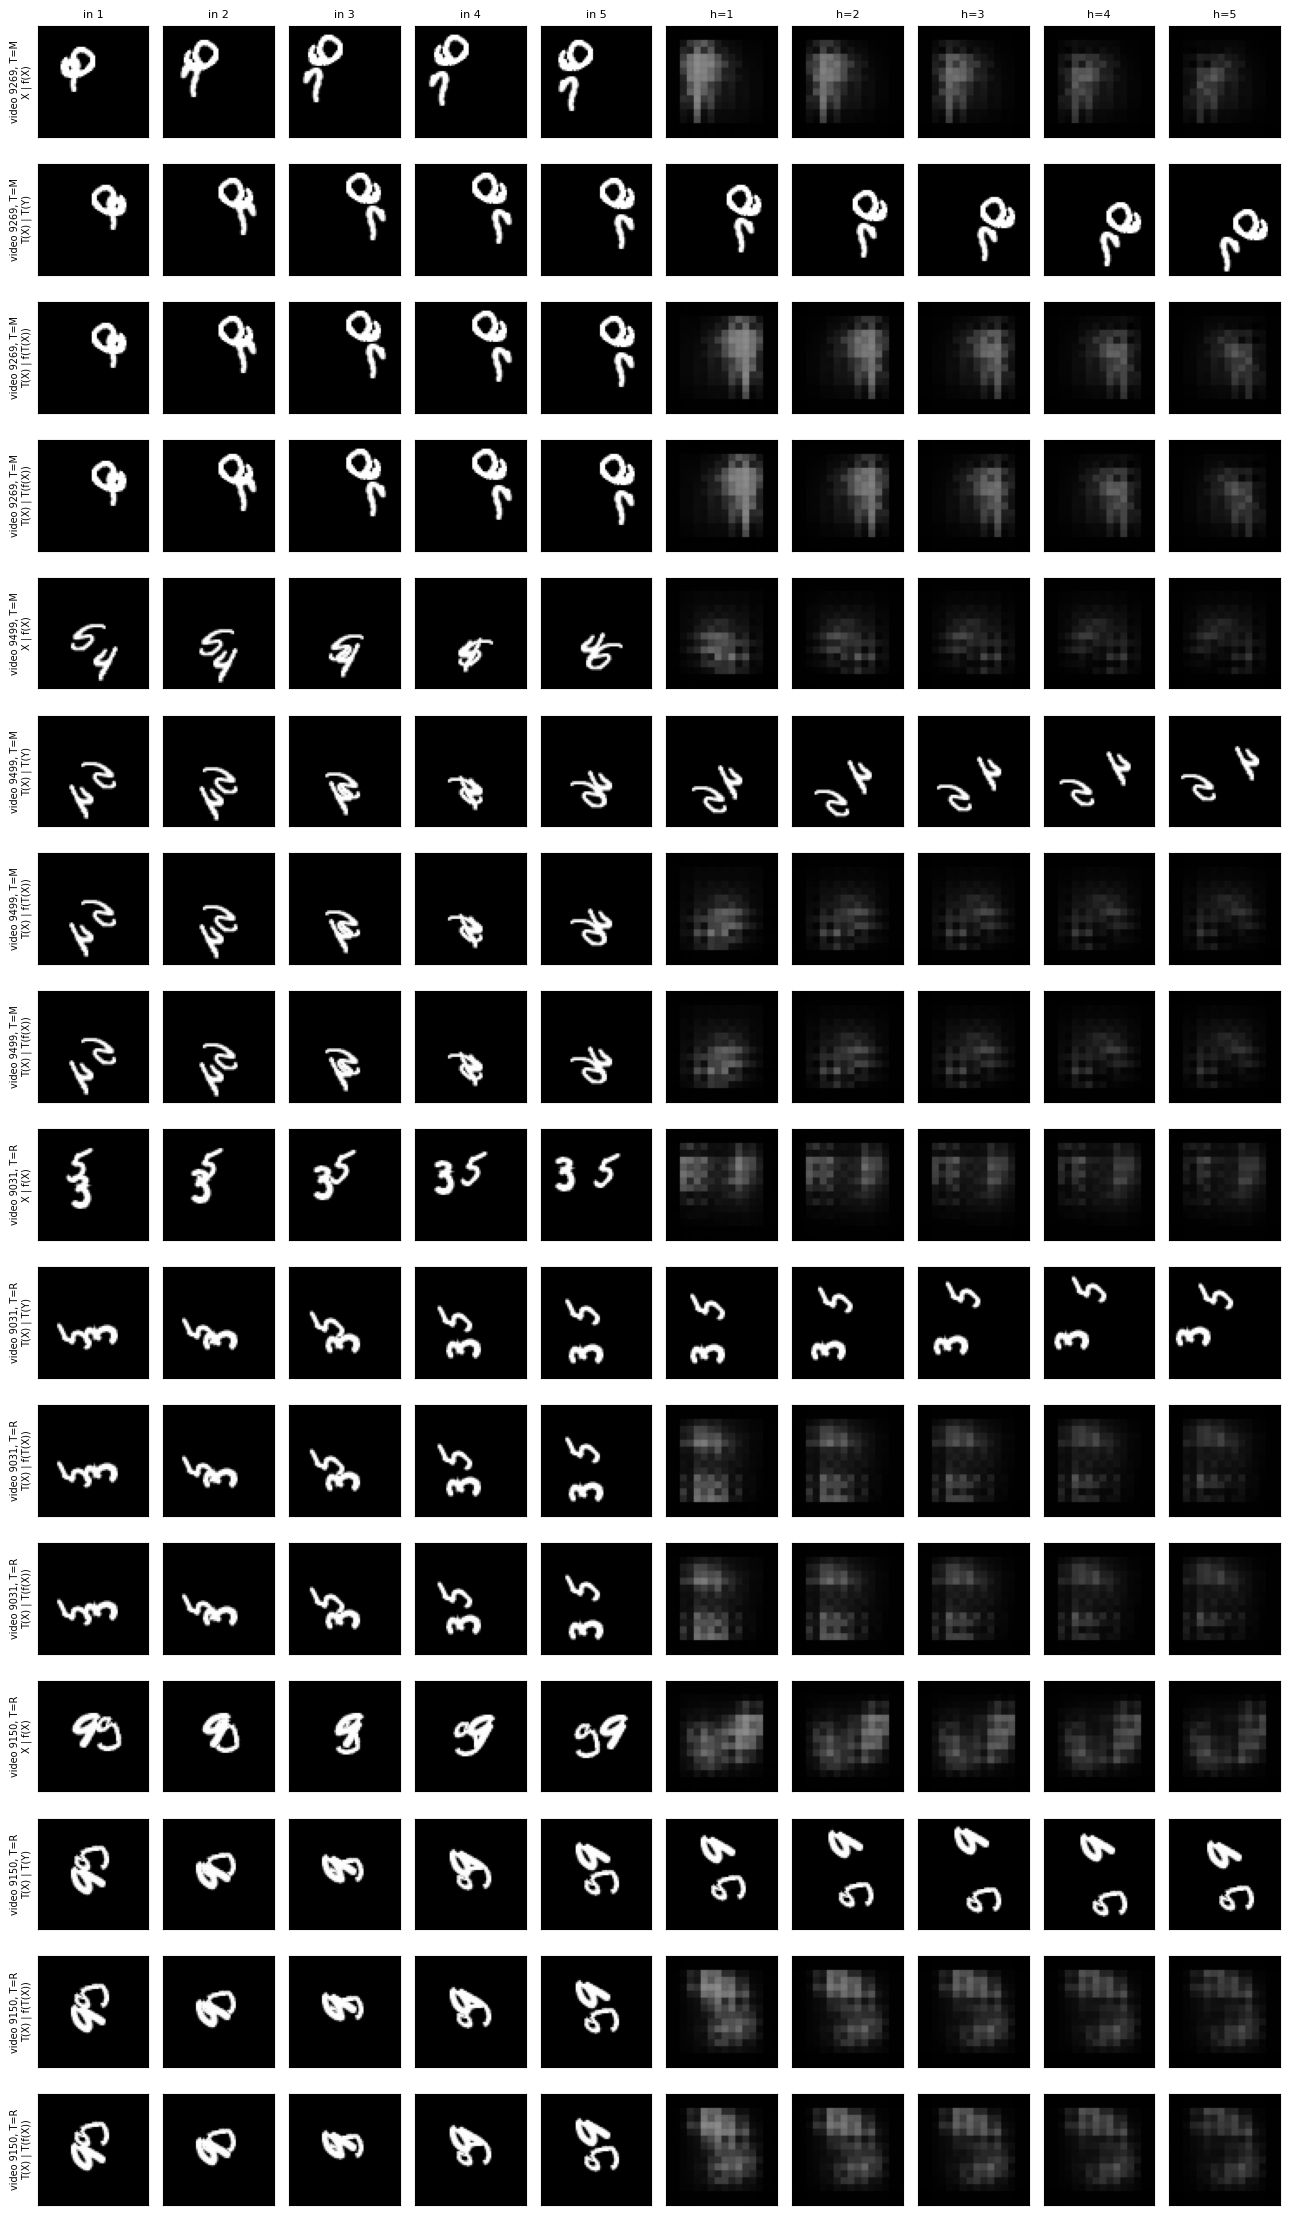

./content/q2/outputs/gifs/fig6a_symD_video9269_M.gif
./content/q2/outputs/gifs/fig6a_symD_video9499_M.gif
./content/q2/outputs/gifs/fig6a_symD_video9031_R.gif
./content/q2/outputs/gifs/fig6a_symD_video9150_R.gif


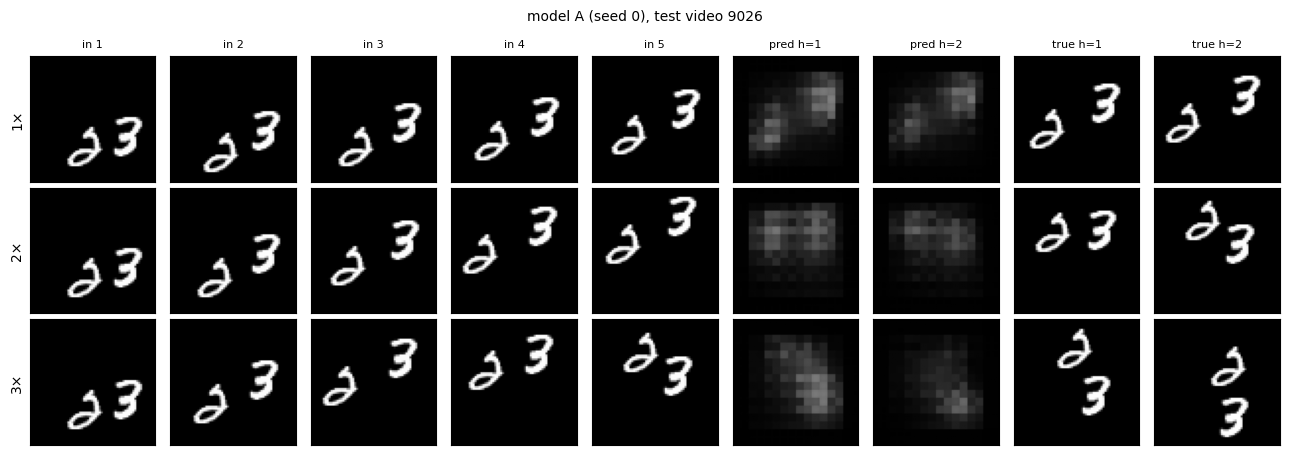

In [28]:
fD0 = symmetrise(models['D'][0])

plot_fig3(fD0, picks, 'figure6a.png')
for v, tname, T in picks:
  pth = f'{out}/gifs/fig6a_symD_video{9000+v}_{tname}.gif'
  make_gif(fD0, v, T, pth)
  print(pth)

plot_fig5(fD0, good[0], 'figure6b.png')